# $Rocio$ $Argote$ $Hermosilla$

## 22.373.783-8

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
rng = np.random.default_rng(seed=3559)

## Ejercicio 1

##### Un catalogo astronomico contiene informacion sobre las propiedades fısicas de objetos celestes, como su luminosidad, radio, distancia y temperatura efectiva. Estas propiedades permiten estudiar las caracterısticas de las estrellas y determinar cuales pueden ser detectadas por un instrumento astronomico.

In [3]:
# PARTE I: creo radios para los datos entregados (100 estrellas)
radio_estelar = rng.uniform(0.5, 5, 100)

# creo distancias para los datos entregados (100 estrellas)
distancia = rng.uniform(50, 500, 100)

#creo las temperaturas de los datos entregados (100 estrellas)
temperaturas = rng.uniform(3000, 10000, 100)

#se utiliza rng.uniform(minimo, maximo, num cantidad) para crear numeros aleatorios dentro de los intervalos correspondientes.

In [4]:
# PARTE II: construyo un DataFrame en pandas
#DataFrame() crea una tabla,
#{} generas las columnas de la tabla
catalogo = pd.DataFrame({"Identificador de la estrella": np.arange(1, 101),
                         "Radio estelar (R⊙)" : radio_estelar,
                         "Distancia (pc)" : distancia,

                         "Temperatura (K)" : temperaturas})

#mostro las 100 estrellas, una fila debajo de otra.
print(catalogo.to_string(index=False))


 Identificador de la estrella  Radio estelar (R⊙)  Distancia (pc)  Temperatura (K)
                            1            2.526253      222.822970      9936.897625
                            2            4.327135      303.463710      9381.889330
                            3            1.046682      482.490883      6749.285960
                            4            3.767895      395.901145      7787.421776
                            5            0.570846      413.715263      7413.220244
                            6            2.909676      326.905812      6294.962751
                            7            0.608740      416.851248      5003.136424
                            8            1.987290      372.417338      9067.095460
                            9            2.990084      133.116123      5104.057433
                           10            0.764894      494.234636      9998.416850
                           11            2.185865      444.877463      8410.840764
    

In [5]:
display(catalogo.head(10))
display(catalogo.describe())
#.head(10) slecciona las 10 primeras filas del catálogo,
#.describe() calcula automáticamente distintas estadísticas de las columnas del catálogo

,Identificador de la estrella,Radio estelar (R⊙),Distancia (pc),Temperatura (K)
0,1,2.526253,222.822970,9936.897625
1,2,4.327135,303.463710,9381.889330
2,3,1.046682,482.490883,6749.285960
3,4,3.767895,395.901145,7787.421776
4,5,0.570846,413.715263,7413.220244
5,6,2.909676,326.905812,6294.962751
6,7,0.608740,416.851248,5003.136424
7,8,1.987290,372.417338,9067.095460
8,9,2.990084,133.116123,5104.057433
9,10,0.764894,494.234636,9998.416850


,Identificador de la estrella,Radio estelar (R⊙),Distancia (pc),Temperatura (K)
count,100.000000,100.000000,100.000000,100.000000
mean,50.500000,2.667174,301.267226,7220.774989
std,29.011492,1.226535,124.863306,1978.896559
min,1.000000,0.552546,72.263098,3045.470884
25%,25.750000,1.566167,182.314562,5955.895877
50%,50.500000,2.688776,300.504636,7480.979869
75%,75.250000,3.459086,415.526615,8899.459278
max,100.000000,4.926290,494.997294,9998.416850


In [6]:
#PARTE 3.1: cálculo la luminosidad y el flujo observado,
#Antes de Calcular la luminosidad en luminosidad es solares, se debe hacer una conversión


#Temperatura efectiva del sol, en Kelvin
temperatura_sol = 5778

#luminosidad de cada estrella en luminosidades solares
luminosidades = radio_estelar**2 * (temperaturas / temperatura_sol)**4


#agrego las luminosidades como una nueva columna del catálogo.
catalogo["Luminosidad (Lum_solar)"] = luminosidades


#!!!Esto es innecesario, solo para hacerlo mas ordenado 
#así evito que Pandas separe las columnas en dos bloques
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)


In [7]:
#PARTE 3.2 : ahora calculo cuánto flujo de energía recibimos de cada estrella
# Hago conversiones

#luminosidad del Sol en vatios
luminosidad_sol = 3.828e26
#un pársec expresado en metro
parsec_metros = 3.086e16


#convierto las luminosidades solares a vatios
luminosidad_vatios = luminosidades * luminosidad_sol
#convierto las distancias de pársecs a metros.
distancias_metros = distancia * parsec_metros

#creo la variable flujo recibido usando la fórmula dada
flujos = luminosidad_vatios / (4 * np.pi * distancias_metros**2)

#agrego el flujo como una nueva columna del catálogo
catalogo["Flujo (W/m²)"] = flujos

#muestro las primeras 10 estrellas con el flujo calculado
print(catalogo.head(10).to_string(index=False))


 Identificador de la estrella  Radio estelar (R⊙)  Distancia (pc)  Temperatura (K)  Luminosidad (Lum_solar)  Flujo (W/m²)
                            1            2.526253      222.822970      9936.897625                55.827322  3.596641e-11
                            2            4.327135      303.463710      9381.889330               130.152304  4.520730e-11
                            3            1.046682      482.490883      6749.285960                 2.039625  2.802479e-13
                            4            3.767895      395.901145      7787.421776                46.844898  9.560025e-12
                            5            0.570846      413.715263      7413.220244                 0.882989  1.650147e-13
                            6            2.909676      326.905812      6294.962751                11.927567  3.570071e-12
                            7            0.608740      416.851248      5003.136424                 0.208316  3.834697e-14
                        

In [8]:
#PARTE 3.3: min y max de la luminosidad y el flujo, (aqui profe disculpeme no entendi si queria el valor o la posicion, puse ambas)

#posición de la estrella con mayor y menor luminosidad
pos_max_luminosidad = np.argmax(luminosidades)
pos_min_luminosidad = np.argmin(luminosidades)
#y su valor
max_lum = np.max(luminosidades)
min_lum = np.min(luminosidades)


#posición de la estrella con mayor y menor flujo observado.
pos_max_flujo = np.argmax(flujos)
pos_min_flujo = np.argmin(flujos)
#y su valor
max_flujo = np.max(flujos)
min_flujo = np.min(flujos)


print("Mayor luminosidad:", max_lum, " " "Estrella:", pos_max_luminosidad + 1)
print("Menor luminosidad:", min_lum, " " "Estrella:", pos_min_luminosidad + 1)

print("Mayor flujo:", max_flujo, " " "Estrella:", pos_max_flujo + 1)
print("Menor flujo:", min_flujo, " " "Estrella:", pos_min_flujo + 1)

#+1 convierte la posición en el identificador de la estrella, porque las creamos en orden del 1 al 100

Mayor luminosidad: 174.56654125967063  Estrella: 37
Menor luminosidad: 0.11728958898932529  Estrella: 20
Mayor flujo: 2.4686717705596137e-10  Estrella: 23
Menor flujo: 3.3386551073443303e-14  Estrella: 83


In [9]:
#Parte 4: clasificacion de estrellas

#defino el flujo min que necesita el telescopio para detectar una estrella
limite = 2e-10


#clasificacion de las estrellas según su flujo observado
#si el flujo alcanza el límite, la estrella es detectada
#si no lo alcanza, la estrella no es detectada
catalogo["Clasificacion"] = np.where(catalogo["Flujo (W/m²)"] >= limite, "Detectada", "No detectada")

print(catalogo.head(10))



   Identificador de la estrella  Radio estelar (R⊙)  Distancia (pc)  Temperatura (K)  Luminosidad (Lum_solar)  Flujo (W/m²) Clasificacion
0                             1            2.526253      222.822970      9936.897625                55.827322  3.596641e-11  No detectada
1                             2            4.327135      303.463710      9381.889330               130.152304  4.520730e-11  No detectada
2                             3            1.046682      482.490883      6749.285960                 2.039625  2.802479e-13  No detectada
3                             4            3.767895      395.901145      7787.421776                46.844898  9.560025e-12  No detectada
4                             5            0.570846      413.715263      7413.220244                 0.882989  1.650147e-13  No detectada
5                             6            2.909676      326.905812      6294.962751                11.927567  3.570071e-12  No detectada
6                             7   

In [10]:
# Contamos cuántas estrellas hay en cada categoría
print(catalogo["Clasificacion"].value_counts())


Clasificacion
No detectada    98
Detectada        2
Name: count, dtype: int64


In [11]:
#cuántas estrellas fueron detectadas
detectadas = (catalogo["Clasificacion"] == "Detectada").sum()

#calculo el porcentaje de estrellas detectadas
porcentaje = detectadas / len(catalogo) * 100

print("Porcentaje de estrellas detectadas:", porcentaje, "%")


Porcentaje de estrellas detectadas: 2.0 %


In [12]:
#agrupo las estrellas según su clasificación
grupos = catalogo.groupby("Clasificacion")

#calculo el flujo, la distancia y la temperatura promedio de cada grupo
print(grupos[["Flujo (W/m²)", "Distancia (pc)", "Temperatura (K)"]].mean())


               Flujo (W/m²)  Distancia (pc)  Temperatura (K)
Clasificacion                                               
Detectada      2.259000e-10      129.655839      9552.105351
No detectada   1.564477e-11      304.769500      7173.196818


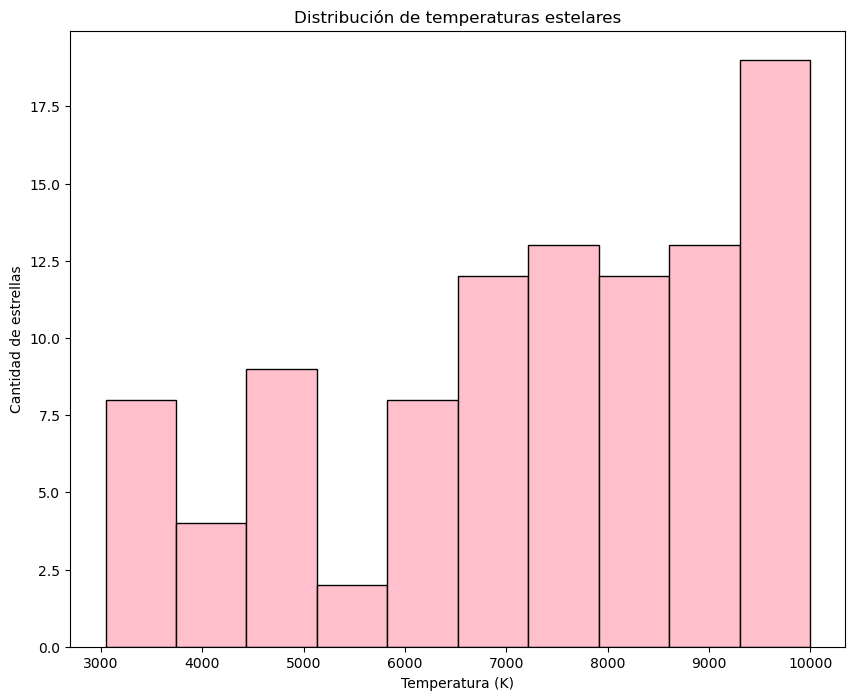

In [13]:
#PARTE 5, grafico

#espacio del tamaño gráfico
plt.figure(figsize=(10, 8))

#distribución de las temperaturas de las estrellas
plt.hist(temperaturas, bins=10, color="pink" , edgecolor="black")


#titulo y los nombres de los ejes con sus unidades
plt.title("Distribución de temperaturas estelares")
plt.xlabel("Temperatura (K)")
plt.ylabel("Cantidad de estrellas")
plt.show()

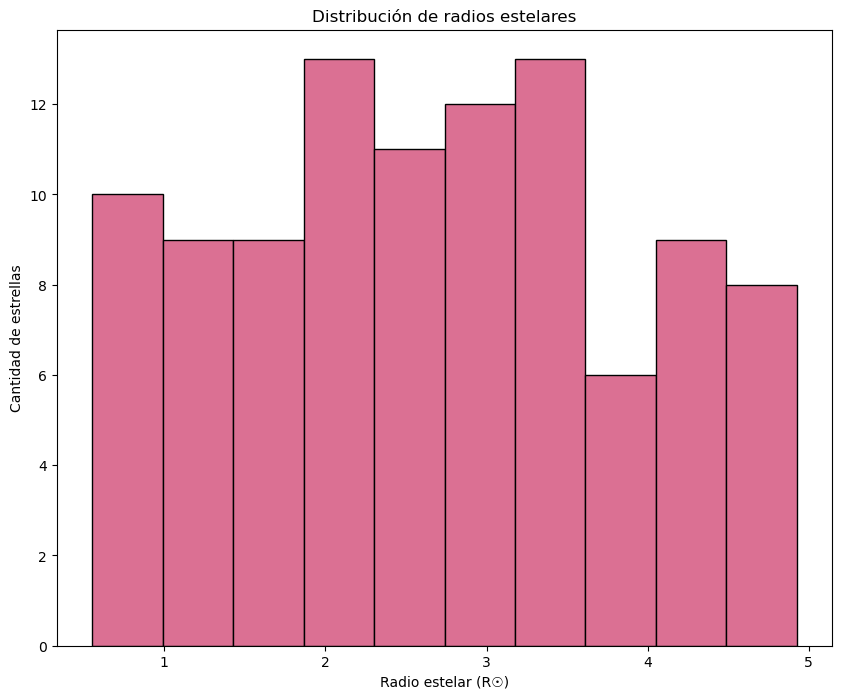

In [14]:
# PARTE 5.2:
#espacio para el gráfico
plt.figure(figsize=(10, 8))

#muestro la distribución de los radios
plt.hist(radio_estelar, bins=10, color="palevioletred", edgecolor="black")

#agrego el título y los nombres de los ejes
plt.title("Distribución de radios estelares")
plt.xlabel("Radio estelar (R☉)")
plt.ylabel("Cantidad de estrellas")
plt.show()


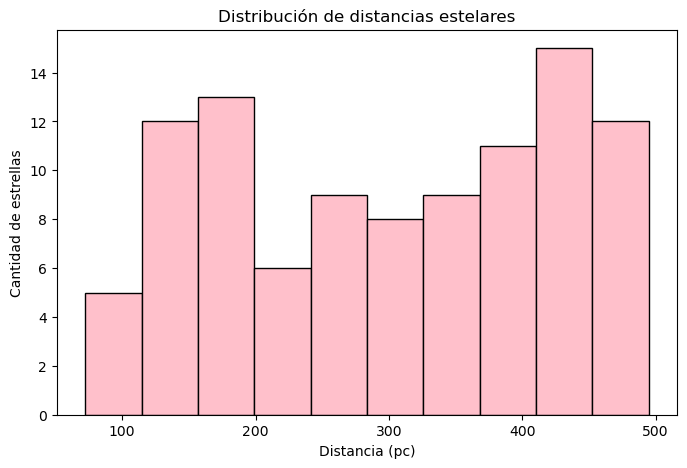

In [15]:
# PARTE 5.3: Histograma de distancias

#creo el espacio para el gráfico
plt.figure(figsize=(8, 5))

#dibujo elhistograma
plt.hist(distancia, bins=10, color="pink", edgecolor="black")

#agrego el título y los nombres de los ejes
plt.title("Distribución de distancias estelares")
plt.xlabel("Distancia (pc)")
plt.ylabel("Cantidad de estrellas")
plt.show()


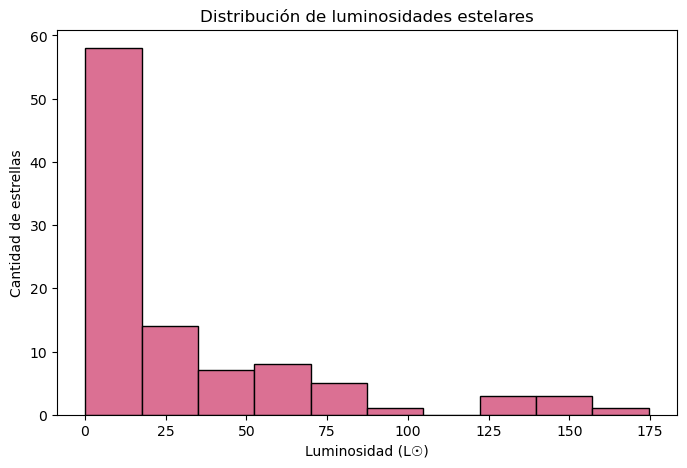

In [16]:
# PARTE 5.4: Histograma de luminosidades.
#creo el espacio para el gráfico
plt.figure(figsize=(8, 5))

#dibujo el histograma de luminosidad
plt.hist(luminosidades, bins=10, color="palevioletred", edgecolor="black")

#agrego el título y los nombres de los ejes
plt.title("Distribución de luminosidades estelares")
plt.xlabel("Luminosidad (L☉)")
plt.ylabel("Cantidad de estrellas")
plt.show()


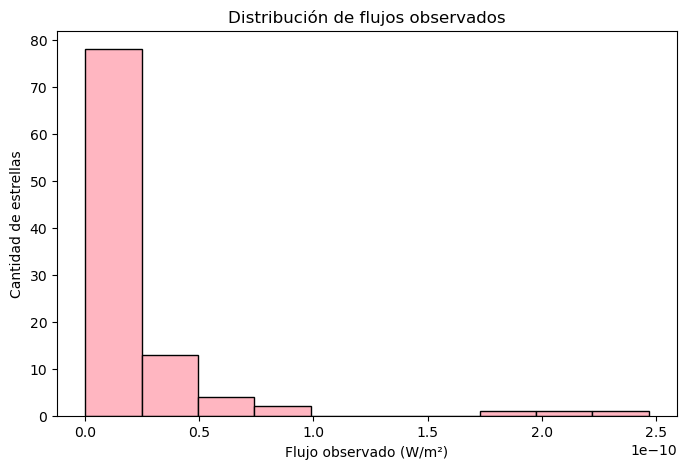

In [17]:
# PARTE 5.5: Histograma de flujos observados

#creo el espacio para el gráfico
plt.figure(figsize=(8, 5))

#dibujo el histograma de flujos observados
plt.hist(flujos, bins=10, color="lightpink", edgecolor="black")

#agregamos el título y los nombres de los ejes
plt.title("Distribución de flujos observados")
plt.xlabel("Flujo observado (W/m²)")
plt.ylabel("Cantidad de estrellas")
plt.show()


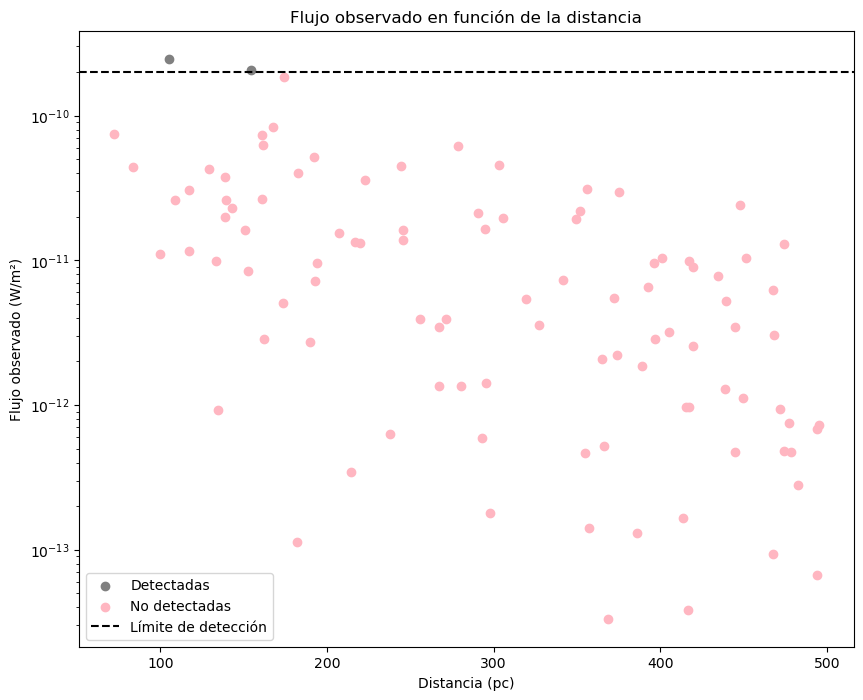

In [18]:
# PARTE 5.6: Flujo observado en función de la distancia

#seleccion de estrellas detectadas
detectadas = catalogo["Clasificacion"] == "Detectada"

#seleccion de estrellas no detectadas
no_detectadas = catalogo["Clasificacion"] == "No detectada"

#creo el espacio para el gráfico
plt.figure(figsize=(10, 8))

#dibujo las estrellas detectadas
plt.scatter(distancia[detectadas], flujos[detectadas], color="grey", label="Detectadas")

#dibujo las estrellas no detectadas
plt.scatter(distancia[no_detectadas], flujos[no_detectadas], color="lightpink", label="No detectadas")

#dibujo una línea horizontal con el límite del telescopio
plt.axhline(limite, color="black", linestyle="--",label="Límite de detección")

#uso una escala logarítmica en el eje vertical
plt.yscale("log")

#agrego el título, los ejes y la leyenda
plt.title("Flujo observado en función de la distancia")
plt.xlabel("Distancia (pc)")
plt.ylabel("Flujo observado (W/m²)")
plt.legend()
plt.show()


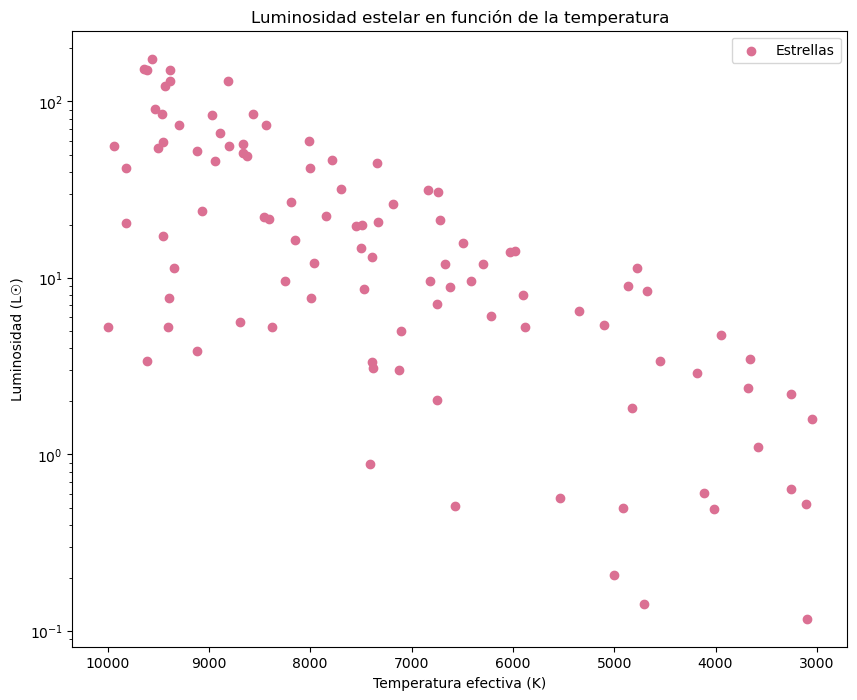

In [19]:
# PARTE 5.7 ): Luminosidad en función de la temperatura

#creao el espacio para el gráfico
plt.figure(figsize=(10, 8))

#dibujo cada estrella
plt.scatter(temperaturas, luminosidades, color="palevioletred", label="Estrellas")

#uso una escala logarítmica para la luminosidad
plt.yscale("log")

#invierto el eje de temperatura para que vaya de mayor a menor
plt.gca().invert_xaxis()

#añado el título y los nombres de los ejes
plt.title("Luminosidad estelar en función de la temperatura")
plt.xlabel("Temperatura efectiva (K)")
plt.ylabel("Luminosidad (L☉)")
plt.legend()
plt.show()


In [20]:
# Contamos las estrellas de cada categoría.
print(catalogo["Clasificacion"].value_counts())

# Calculamos el porcentaje de estrellas detectadas.
detectadas = (catalogo["Clasificacion"] == "Detectada").sum()
porcentaje = detectadas / len(catalogo) * 100

print("Porcentaje detectadas:", porcentaje, "%")



Clasificacion
No detectada    98
Detectada        2
Name: count, dtype: int64
Porcentaje detectadas: 2.0 %
